# Comparación de modelos y selección del mejor

En los notebooks anteriores cada modelo escogió su mejor versión:

- **Modelo 1 (Regresión, notebook 03):** Versión A con Dropout. Predice la nota final G3 (0 a 20).
- **Modelo 2 (Clasificación multiclase, notebook 04):** Versión A sin Dropout. Predice el nivel de riesgo (1 a 4).

En este notebook comparamos esos dos modelos para escoger el mejor para la alerta temprana. No se entrena nada nuevo: cargamos los modelos guardados en `models/` (los mismos que usa la API) y los probamos con los 209 estudiantes de test.

El problema es que no se pueden comparar directamente: el Modelo 1 da una nota y se mide con MAE y RMSE, y el Modelo 2 da un nivel y se mide con accuracy, precisión, recall y F1.

Para poder compararlos, convertimos la nota que predice el Modelo 1 en nivel de riesgo, con la misma regla que usamos en el preprocesamiento para crear `nivel_riesgo` (método `calcular_nivel_riesgo` de la clase `Preprocesador`). Así los dos modelos responden la misma pregunta: ¿en qué nivel de riesgo está el estudiante?

# 1.Importación librerías

In [1]:
import sys
sys.path.append('..') #para poder importar la carpeta src desde notebooks/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.models import load_model
from sklearn.metrics import mean_absolute_error, mean_squared_error, explained_variance_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

from src import config
from src.data_prep import Preprocesador
from src.train.model1 import ModeloRegresion
from src.train.model2 import ModeloClasificacion

# 2.Importación de datos y modelos

In [2]:
#Mismos datos procesados que usaron los notebooks 03 y 04
train = pd.read_csv(config.RUTA_PROCESSED / 'train.csv')
test = pd.read_csv(config.RUTA_PROCESSED / 'test.csv')

In [3]:
train.shape, test.shape

((835, 64), (209, 64))

In [4]:
#Cada objeto prepara sus datos igual que en su notebook (mismas columnas y escalado ajustado solo con train)
modelo1 = ModeloRegresion(version='A', usar_dropout=True)
X_train_1, X_test_1, y_train_1, y_test_nota = modelo1.preparar_datos(train, test)

modelo2 = ModeloClasificacion(version='A', usar_dropout=False)
X_train_2, X_test_2, y_train_2, y_test_nivel = modelo2.preparar_datos(train, test)

In [5]:
X_test_1.shape, X_test_2.shape

((209, 62), (209, 62))

In [6]:
#Cargamos los modelos ya entrenados (los mismos que usa la API)
modelo1.modelo = load_model(config.RUTA_MODELS / 'model1.keras')
modelo2.modelo = load_model(config.RUTA_MODELS / 'model2.keras')

# 3.Predicciones

## 3.1 Modelo 1: de la nota al nivel de riesgo
El Modelo 1 predice la nota y después la pasamos a nivel con la misma regla del preprocesamiento:

| Nivel | Nota | Significado |
|---|---|---|
| 1 | 14 - 20 | Sin riesgo |
| 2 | 12 - 13 | Riesgo bajo |
| 3 | 10 - 11 | Riesgo medio |
| 4 | 0 - 9 | Riesgo alto (reprueba) |

Lo hacemos igual que la API (`/predict/grade`): la nota no se redondea, entonces por ejemplo un 9.6 queda como riesgo alto.

In [7]:
nota_predicha = modelo1.predecir(X_test_1)

In [8]:
#Convertimos cada nota predicha en nivel de riesgo con el método de la clase Preprocesador
prep = Preprocesador()
nivel_modelo1 = pd.Series(nota_predicha).apply(lambda x: prep.calcular_nivel_riesgo(x))

In [9]:
#Comparamos algunas notas reales y predichas con el nivel que resulta
pd.DataFrame({'Nota real': y_test_nota.values,
              'Nota predicha': nota_predicha.round(2),
              'Nivel real': test['nivel_riesgo'].values,
              'Nivel Modelo 1': nivel_modelo1.values}).head(10)

,Nota real,Nota predicha,Nivel real,Nivel Modelo 1
0,11,11.33,3,3
1,13,13.87,2,2
2,16,14.98,1,1
3,11,10.62,3,3
4,10,11.67,3,3
5,8,8.87,4,4
6,15,13.92,1,2
7,8,6.74,4,4
8,5,7.36,4,4
9,9,10.08,4,3


## 3.2 Modelo 2: nivel de riesgo directo
El Modelo 2 no pasa por la nota. Su capa de salida tiene 4 neuronas con softmax (una por nivel) y se escoge el nivel con la probabilidad más alta.

In [10]:
nivel_modelo2 = modelo2.predecir(X_test_2)
nivel_real = test['nivel_riesgo'].values

In [11]:
pd.DataFrame({'Nivel real': nivel_real,
              'Nivel Modelo 1': nivel_modelo1.values,
              'Nivel Modelo 2': nivel_modelo2}).head(10)

,Nivel real,Nivel Modelo 1,Nivel Modelo 2
0,3,3,3
1,2,2,2
2,1,1,1
3,3,3,3
4,3,3,3
5,4,4,4
6,1,2,1
7,4,4,3
8,4,4,4
9,4,3,3


# 4.Métricas de cada modelo en su propia tarea
Primero revisamos que los modelos cargados den los mismos resultados que en sus notebooks.

In [12]:
#Modelo 1: métricas de regresión (sobre la nota)
print('MAE:', mean_absolute_error(y_test_nota, nota_predicha))
print('RMSE:', np.sqrt(mean_squared_error(y_test_nota, nota_predicha)))
print('Varianza explicada:', explained_variance_score(y_test_nota, nota_predicha))

MAE: 1.1357102394104004
RMSE: 1.699235025963717
Varianza explicada: 0.8239449858665466


In [13]:
#Modelo 2: métricas de clasificación (sobre el nivel)
print('Accuracy:', accuracy_score(nivel_real, nivel_modelo2))
print('F1:', f1_score(nivel_real, nivel_modelo2, average='weighted'))

Accuracy: 0.7320574162679426
F1: 0.7329397342989429


# 5.Comparación en la misma tarea: nivel de riesgo
Ahora medimos los dos modelos con las mismas métricas:

- **Accuracy:** de todos los estudiantes, ¿a cuántos les acertó el nivel?
- **Precisión:** cuando el modelo dice que un estudiante está en un nivel, ¿cuántas veces acierta?
- **Recall:** de los estudiantes que realmente están en un nivel, ¿a cuántos encontró el modelo?
- **F1:** combina precisión y recall en un solo número.

Usamos `average='weighted'` (promedio ponderado) porque los 4 niveles no tienen la misma cantidad de estudiantes.

In [14]:
#Función para no repetir el mismo cálculo con los dos modelos
def metricas_nivel(nivel_predicho):
    return {'Accuracy': accuracy_score(nivel_real, nivel_predicho),
            'Precisión': precision_score(nivel_real, nivel_predicho, average='weighted'),
            'Recall': recall_score(nivel_real, nivel_predicho, average='weighted'),
            'F1': f1_score(nivel_real, nivel_predicho, average='weighted')}

In [15]:
comparacion = pd.DataFrame([metricas_nivel(nivel_modelo1), metricas_nivel(nivel_modelo2)],
                           index=['Modelo 1 (Regresión)', 'Modelo 2 (Clasificación)'])
comparacion.round(3)

,Accuracy,Precisión,Recall,F1
Modelo 1 (Regresión),0.718,0.750,0.718,0.712
Modelo 2 (Clasificación),0.732,0.736,0.732,0.733


En las métricas generales los dos modelos quedan **muy parecidos** (entre 71 % y 73 %). El Modelo 2 tiene un poco más de accuracy, lo cual es lógico porque se entrenó justamente para clasificar niveles, mientras que el Modelo 1 se entrenó para acertar la nota.

Pero en alerta temprana no todos los errores son igual de graves, así que revisamos el resultado de cada nivel.

In [16]:
etiquetas = ['Sin riesgo (1)', 'Riesgo bajo (2)', 'Riesgo medio (3)', 'Riesgo alto (4)']

In [17]:
print('MODELO 1 (Regresión)')
print(classification_report(nivel_real, nivel_modelo1, target_names=etiquetas))

MODELO 1 (Regresión)
                  precision    recall  f1-score   support

  Sin riesgo (1)       1.00      0.54      0.70        50
 Riesgo bajo (2)       0.59      0.69      0.64        42
Riesgo medio (3)       0.66      0.62      0.64        56
 Riesgo alto (4)       0.74      0.97      0.84        61

        accuracy                           0.72       209
       macro avg       0.75      0.71      0.70       209
    weighted avg       0.75      0.72      0.71       209



In [18]:
print('MODELO 2 (Clasificación)')
print(classification_report(nivel_real, nivel_modelo2, target_names=etiquetas))

MODELO 2 (Clasificación)
                  precision    recall  f1-score   support

  Sin riesgo (1)       0.78      0.78      0.78        50
 Riesgo bajo (2)       0.57      0.55      0.56        42
Riesgo medio (3)       0.67      0.75      0.71        56
 Riesgo alto (4)       0.88      0.80      0.84        61

        accuracy                           0.73       209
       macro avg       0.72      0.72      0.72       209
    weighted avg       0.74      0.73      0.73       209



# 6.Matrices de confusión
Las filas son el nivel real y las columnas el nivel que predijo el modelo. Los números de la diagonal son los aciertos.

In [19]:
matriz1 = confusion_matrix(nivel_real, nivel_modelo1)
matriz2 = confusion_matrix(nivel_real, nivel_modelo2)

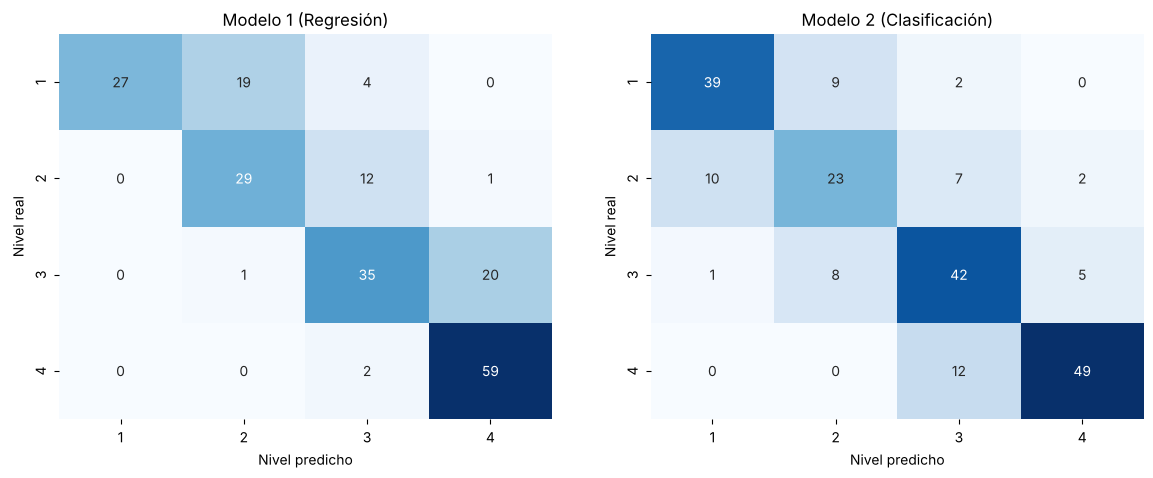

In [20]:
plt.figure(figsize=(14,5))

plt.subplot(1,2,1)
sns.heatmap(matriz1, annot=True, fmt='d', cmap='Blues', cbar=False, xticklabels=[1,2,3,4], yticklabels=[1,2,3,4])
plt.title('Modelo 1 (Regresión)')
plt.xlabel('Nivel predicho')
plt.ylabel('Nivel real')

plt.subplot(1,2,2)
sns.heatmap(matriz2, annot=True, fmt='d', cmap='Blues', cbar=False, xticklabels=[1,2,3,4], yticklabels=[1,2,3,4])
plt.title('Modelo 2 (Clasificación)')
plt.xlabel('Nivel predicho')
plt.ylabel('Nivel real')

plt.show()

En las dos matrices los errores quedan **al lado de la diagonal**: cuando un modelo se equivoca, normalmente es por un solo nivel (por ejemplo, confunde riesgo medio con riesgo alto). Ninguno de los dos confunde un estudiante sin riesgo con uno de riesgo alto.

La diferencia importante está en la **última fila (riesgo alto)**: el Modelo 1 pone casi a todos los estudiantes que reprueban en la columna 4, mientras que el Modelo 2 deja a varios en la columna 3 (riesgo medio).

# 7.Estudiantes en riesgo alto (los que reprueban)
El objetivo del sistema es **detectar a tiempo a los estudiantes que van a reprobar** para poder ayudarlos. Por eso revisamos con más detalle el nivel 4.

In [21]:
#Función para contar aciertos y errores en riesgo alto (nivel 4)
def resumen_riesgo_alto(nivel_predicho):
    detectados = ((nivel_real == 4) & (nivel_predicho == 4)).sum()  #reprueban y el modelo dijo riesgo alto
    se_escapan = ((nivel_real == 4) & (nivel_predicho != 4)).sum()  #reprueban pero el modelo NO dijo riesgo alto
    falsas_alarmas = ((nivel_real != 4) & (nivel_predicho == 4)).sum()  #el modelo dijo riesgo alto pero no reprueban
    return {'Detectados': detectados,
            'Se escapan': se_escapan,
            'Falsas alarmas': falsas_alarmas}

In [22]:
riesgo_alto = pd.DataFrame([resumen_riesgo_alto(nivel_modelo1.values), resumen_riesgo_alto(nivel_modelo2)],
                           index=['Modelo 1 (Regresión)', 'Modelo 2 (Clasificación)'])
riesgo_alto

,Detectados,Se escapan,Falsas alarmas
Modelo 1 (Regresión),59,2,21
Modelo 2 (Clasificación),49,12,7


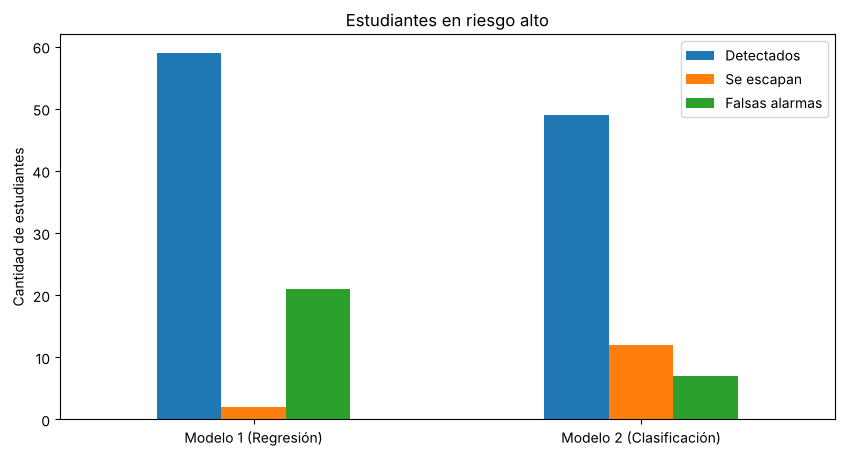

In [23]:
riesgo_alto.plot(kind='bar', figsize=(10,5), rot=0)
plt.title('Estudiantes en riesgo alto')
plt.ylabel('Cantidad de estudiantes')
plt.show()

De los 61 estudiantes de test que reprueban:

- **Se escapan:** estudiantes que sí reprueban pero el modelo no los marcó como riesgo alto. Es el **error más grave**, porque ese estudiante no recibiría ayuda a tiempo.
- **Falsas alarmas:** estudiantes marcados como riesgo alto que al final no reprueban. Es un error **menos grave**: el docente revisa el caso y le da seguimiento a alguien que no lo necesitaba tanto.

Al Modelo 1 se le escapan muchos menos estudiantes que al Modelo 2, pero da más falsas alarmas. Esto coincide con el `classification_report`: en riesgo alto el Modelo 1 tiene más **recall** (encuentra a más de los que reprueban) y el Modelo 2 tiene más **precisión** (cuando dice riesgo alto, acierta más veces).

# 8.Conclusión y selección del modelo

**Escogemos el Modelo 1 (Regresión, Versión A con Dropout).**

**¿Por qué?**

1. **Se le escapan menos estudiantes que van a reprobar.** Para un sistema de alerta temprana preferimos revisar a un estudiante de más (falsa alarma) que dejar a uno sin ayuda.
2. **Da más información.** El Modelo 1 da la nota esperada y con esa nota también sacamos el nivel de riesgo, así que cubre las dos partes del objetivo del proyecto. Además, una nota es fácil de entender para un docente.
3. **En las métricas generales quedan parecidos.** La diferencia en accuracy y F1 entre los dos modelos es pequeña, entonces escoger el Modelo 1 no significa perder mucha exactitud.

**¿Qué perdemos?** El Modelo 1 da más falsas alarmas y su accuracy es un poco menor. Por eso dejamos **los dos modelos** en la API (`/predict/grade` y `/predict/risk_level`): el Modelo 2 sirve como segunda opinión, y si los dos dicen riesgo alto, la alerta es más confiable.

**Limitaciones:**

- Los modelos escogidos usan la **Versión A** (con las notas parciales G1 y G2), que es la que da buenos resultados, pero solo se puede usar desde el segundo periodo, cuando ya hay notas. La **Versión B** (sin G1 ni G2) se puede usar desde el inicio del año, pero con mucho más error (MAE de casi 2.7 puntos). Recomendamos usar la Versión B como una primera señal al inicio del año y la Versión A cuando ya existan notas parciales.
- Ningún modelo predice bien a los estudiantes con nota final 0 (posible abandono), porque sus notas parciales no siempre lo anticipan.
- Al entrenar una red neuronal hay algo de aleatoriedad: aunque usamos semilla fija (101), si se vuelve a entrenar en otra computadora los resultados pueden cambiar un poco. Por eso la API y el dashboard usan los modelos ya guardados en `models/`.